# Chapter 11 · Probability: companion notebook
*Data Science and Artificial Intelligence in Health, Volume 1*

> **This notebook accompanies the book chapter; it does not reproduce it.** Definitions, derivations, and explanations are in the book. Here you run the calculations on the case and check the numbers. All data are **synthetic**; no real patients appear.

**Part A** follows the chapter's case, a public maternity unit with 5,000 delivery records, through the director's four questions. **Part B** gives the code and result for each of the twelve chapter exercises (statements are in the book). Run the cells in order.

## Part A. The case

**Data.** `data/deliveries.csv`: one row per delivery. `stay_days` is the initial postnatal stay (readmission days are not included); the allowance of 4 days is a hypothetical assumption. Each fetal-monitoring alert adds one maternal bed-day, already inside `stay_days`. `acidemia` is a binary flag (cord arterial pH below 7.10); there are no measured pH values.

**Director's questions.** Q1 how often a stay exceeds 4 days · Q2 who has long stays · Q3 what the alert adds in bed-days · Q4 fair selection and sampling · then the bed plan.

In [1]:
import random
from math import comb, factorial, perm

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10})
INK, MUTED = "#222222", "#8a8a8a"

df = pd.read_csv("data/deliveries.csv")
X = df["stay_days"] > 4                      # long stay
D = df["gestational_diabetes"] == "yes"
C = df["cesarean"] == "yes"
H = df["hemorrhage"] == "yes"
R = df["readmission"] == "yes"
T = df["return_to_theatre"] == "yes"
A = df["acidemia"] == "yes"
F = df["monitor_alert"] == "yes"
any_event = H | R | T
print(df.shape)
df.head()

(5000, 10)


,delivery_id,age_years,gestational_diabetes,cesarean,hemorrhage,readmission,return_to_theatre,stay_days,acidemia,monitor_alert
0,D0001,21,no,no,no,no,no,3,no,no
1,D0002,29,no,yes,no,no,no,4,no,no
2,D0003,24,yes,yes,no,yes,no,5,no,yes
3,D0004,22,no,no,no,no,no,3,no,no
4,D0005,48,no,no,no,no,no,2,no,no


### Q1. How often does the stay exceed 4 days?

In [2]:
print(len(df), int(X.sum()), round(X.mean(), 4))
running = X.cumsum() / range(1, len(df) + 1)
checkpoints = (10, 50, 100, 500, 1000, 5000)
print([float(round(running.iloc[k - 1], 4)) for k in checkpoints])

5000 1216 0.2432
[0.3, 0.22, 0.23, 0.228, 0.248, 0.2432]


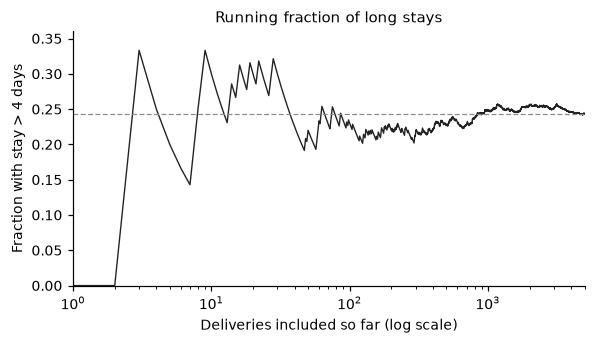

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(df) + 1), running, color=INK, lw=0.9)
ax.axhline(X.mean(), color=MUTED, lw=0.8, ls=(0, (4, 2)))
ax.set(xscale="log", xlim=(1, 5000), ylim=(0, 0.36), xlabel="Deliveries included so far (log scale)",
       ylabel="Fraction with stay > 4 days", title="Running fraction of long stays")
plt.show()

**Result:** 1,216 of 5,000 deliveries (0.2432).

In [4]:
print(int(H.sum()), int(R.sum()), int(T.sum()))
print(int((H & R).sum()), int((H & T).sum()), int(any_event.sum()))
p_h, p_r, p_t = H.mean(), R.mean(), T.mean()
p_hr, p_ht, p_rt, p_hrt = (H & R).mean(), (H & T).mean(), (R & T).mean(), (H & R & T).mean()
print(round(p_h + p_r + p_t, 4))
print(round(p_h + p_r + p_t - p_hr - p_ht - p_rt + p_hrt, 4))
print(round(any_event.mean(), 4), round((~any_event).mean(), 4))

299 398 83
133 54 592
0.156
0.1184
0.1184 0.8816


**Result:** sum of the three probabilities 0.1560; with overlaps removed 0.1184 (direct count 0.1184); complement 0.8816.

### Q2. Who has long stays?

In [5]:
groups = [("D", D), ("not D", ~D), ("C", C), ("not C", ~C),
          ("any H/R/T", any_event), ("no H/R/T", ~any_event)]
for name, group in groups:
    print(name, int(group.sum()), int((X & group).sum()), f"{X[group].mean():.4f}")
print("D and X", f"{(D & X).mean():.4f}")

D 809 396 0.4895
not D 4191 820 0.1957
C 1499 851 0.5677
not C 3501 365 0.1043
any H/R/T 592 335 0.5659
no H/R/T 4408 881 0.1999
D and X 0.0792


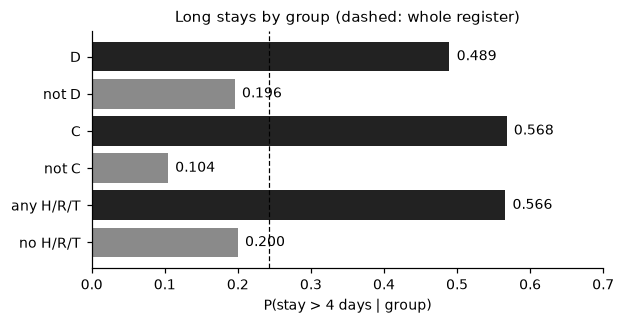

In [6]:
labels = [g[0] for g in groups]
vals = [X[g[1]].mean() for g in groups]
fig, ax = plt.subplots(figsize=(6, 2.8))
bars = ax.barh(labels[::-1], vals[::-1], color=[MUTED, INK] * 3)
ax.axvline(X.mean(), color="black", lw=0.8, ls=(0, (4, 2)))
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
ax.set(xlim=(0, 0.7), xlabel="P(stay > 4 days | group)", title="Long stays by group (dashed: whole register)")
plt.show()

In [7]:
print(f"{H.mean() * R.mean():.8f}", f"{(H & R).mean():.4f}")
print(f"{R[H].mean():.4f}", f"{R[~H].mean():.4f}")
chain = D.mean() * H[D].mean() * R[D & H].mean()
print(f"{chain:.4f}", f"{(D & H & R).mean():.4f}")

0.00476008 0.0266
0.4448 0.0564
0.0090 0.0090


In [8]:
p_x = X[D].mean() * D.mean() + X[~D].mean() * (~D).mean()
print(f"{p_x:.4f}")
for name, group in [("D", D), ("C", C)]:
    posterior = X[group].mean() * group.mean() / p_x
    print(name, f"{posterior:.4f}", f"{group[X].mean():.4f}")

0.2432
D 0.3257 0.3257
C 0.6998 0.6998


**Result:** long stay in 396/809 with diabetes vs 820/4,191 without; 851/1,499 cesareans vs 365/3,501 vaginal births; 335/592 with any recorded adverse event. Among long stays: 396/1,216 diabetes, 851/1,216 cesarean.

### Q3. What does the alert add in bed-days?

In [9]:
print(int((A & F).sum()), int((A & ~F).sum()), int((~A & F).sum()), int((~A & ~F).sum()))
sens = F[A].mean()
spec = (~F)[~A].mean()
prior = A.mean()
posterior = sens * prior / (sens * prior + (1 - spec) * (1 - prior))
print(f"{sens:.4f}", f"{spec:.4f}", f"{prior:.4f}")
print(f"{posterior:.4f}", f"{A[F].mean():.4f}")

197 47 465 4291
0.8074 0.9022 0.0488
0.2976 0.2976


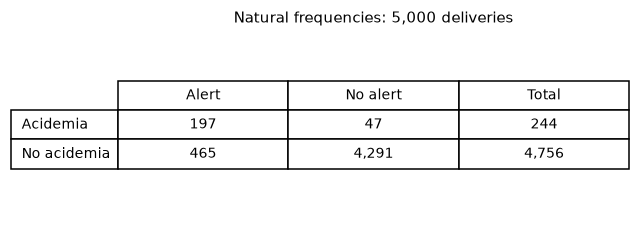

In [10]:
cell = pd.crosstab(A.map({True: "Acidemia", False: "No acidemia"}), F.map({True: "Alert", False: "No alert"}))
cell = cell.loc[["Acidemia", "No acidemia"], ["Alert", "No alert"]]
fig, ax = plt.subplots(figsize=(6, 2.2)); ax.axis("off")
t = ax.table(cellText=[[f"{v:,}" for v in row] + [f"{row.sum():,}"] for _, row in cell.iterrows()],
             rowLabels=cell.index, colLabels=list(cell.columns) + ["Total"], loc="center", cellLoc="center")
t.scale(1, 1.6); ax.set_title("Natural frequencies: 5,000 deliveries")
plt.show()

In [11]:
base_stay = df["stay_days"] - F.astype(int)
added_days = df["stay_days"] - base_stay
excess_added = ((df["stay_days"] - 4).clip(lower=0) - (base_stay - 4).clip(lower=0))
crossed = F & (base_stay <= 4) & X
print(int(added_days.sum()), int(added_days[~A].sum()))
print(int(excess_added.sum()), int(crossed.sum()))
print(int((F & X).sum()), int(F.sum()), f"{X[F].mean():.3f}")
print(int((~F & X).sum()), int((~F).sum()), f"{X[~F].mean():.3f}")

662 465
282 138
282 662 0.426
934 4338 0.215


**Result:** 662 alerts add 662 maternal bed-days, 465 of them after births without acidemia; 282 added days fall beyond day 4; 138 stays cross 4 days because of the added day. The register has no treatment effects, so these counts do not show whether the observation was needed.

### Q4. Fair selection and sampling (hypothetical design inputs)

In [12]:
print(comb(12, 6), 2 * comb(9, 3))
print(f"{2 * comb(9, 3) / comb(12, 6):.4f}")
print(factorial(12), perm(12, 2))
none = comb(388, 20) / comb(400, 20)
print(f"{none:.4f}", f"{1 - none:.4f}")

924 168
0.1818
479001600 132
0.5356 0.4644


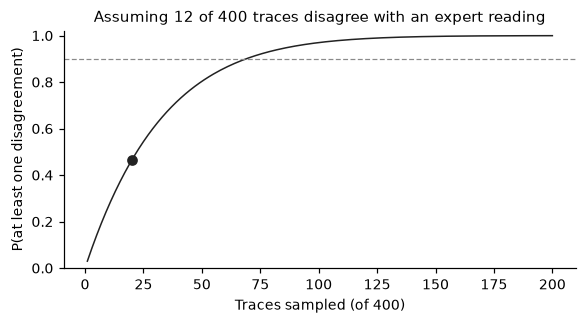

In [13]:
n = np.arange(1, 201)
p_detect = 1 - np.array([comb(388, k) / comb(400, k) for k in n])
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(n, p_detect, color=INK, lw=1); ax.axhline(0.9, color=MUTED, lw=0.8, ls=(0, (4, 2)))
ax.plot([20], [1 - none], "o", color=INK)
ax.set(xlabel="Traces sampled (of 400)", ylabel="P(at least one disagreement)", ylim=(0, 1.02),
       title="Assuming 12 of 400 traces disagree with an expert reading")
plt.show()

**Result:** 924 pilot draws, 168 keeping three named teams together (0.1818); 479,001,600 training orders; 20 of 400 traces finds a disagreement with probability 0.4644.

### Bed plan

In [14]:
mean_stay = df["stay_days"].mean()
print(int(df["stay_days"].sum()))
print(f"{mean_stay:.2f}", f"{4 - mean_stay:.2f}")

17666
3.53 0.47


**Result:** 17,666 initial-stay bed-days; mean 3.53 days, 0.47 below the hypothetical allowance. This is arithmetic only, not evidence of spare capacity.

## Part B. Exercise solutions

Statements are in the book. Exercises marked *alt.* use an alternative scenario defined in the statement.

### Exercise 1. Sample space

**Result:** conceptual exercise; the answer is in the book.

### Exercise 2. The eight probabilities

In [15]:
counts = df.groupby(["hemorrhage", "readmission", "return_to_theatre"]).size()
for outcome, count in counts.items():
    code_ = "".join("Y" if item == "yes" else "N" for item in outcome)
    print(code_, int(count), f"{count / len(df):.4f}")
print("Total", int(counts.sum()), f"{counts.sum() / len(df):.4f}")

NNN 4408 0.8816
NNY 28 0.0056
NYN 264 0.0528
NYY 1 0.0002
YNN 144 0.0288
YNY 22 0.0044
YYN 101 0.0202
YYY 32 0.0064
Total 5000 1.0000


**Result:** readmission alone is the most common description with an adverse event (264, 0.0528), then hemorrhage alone (144, 0.0288).

### Exercise 3. Hemorrhage or return to theatre

In [16]:
print(int((H | T).sum()), f"{(H | T).mean():.4f}")
print(f"{H.mean() * T.mean():.8f}", f"{(H & T).mean():.4f}")

328 0.0656
0.00099268 0.0108


**Result:** 328 deliveries (0.0656); product under independence 0.00099 vs observed 0.0108.

### Exercise 4. Delivery type and long stays

In [17]:
p_x_c = X[C].mean()
p_x_not_c = X[~C].mean()
p_x = p_x_c * C.mean() + p_x_not_c * (~C).mean()
print(f"{p_x_c:.4f}", f"{p_x_not_c:.4f}", f"{p_x_c / p_x_not_c:.2f}")
print(f"{p_x_c * C.mean() / p_x:.4f}", f"{C[X].mean():.4f}")

0.5677 0.1043 5.45
0.6998 0.6998


**Result:** 0.5677 vs 0.1043 (ratio 5.45); P(C|X) = 851/1,216 = 0.6998 by Bayes and by count.

### Exercise 5. Three events in sequence

In [18]:
chain = C.mean() * H[C].mean() * T[C & H].mean()
print(int(C.sum()), int((C & H).sum()), int((C & H & T).sum()))
print(f"{chain:.4f}", f"{(C & H & T).mean():.4f}")

1499 114 29
0.0058 0.0058


**Result:** (1,499/5,000) × (114/1,499) × (29/114) = 29/5,000 = 0.0058.

### Exercise 6. Alternative alert (alt.)

In [19]:
scenarios = [(0.95, A.mean()), (0.95, 0.20), (0.80, A.mean())]
for sensitivity, prevalence in scenarios:
    ppv = sensitivity * prevalence / (sensitivity * prevalence + 0.10 * (1 - prevalence))
    print(f"{sensitivity:.2f}", f"{prevalence:.4f}", f"{ppv:.4f}")

0.95 0.0488 0.3277
0.95 0.2000 0.7037
0.80 0.0488 0.2910


**Result:** PPV 0.3277, 0.7037, and 0.2910 under the assumed performance values.

### Exercise 7. Scaled natural frequencies

In [20]:
scale = 10_000 / len(df)
table = pd.DataFrame({"Alert": [(A & F).sum() * scale, (~A & F).sum() * scale],
                      "No alert": [(A & ~F).sum() * scale, (~A & ~F).sum() * scale]},
                     index=["Acidemia present", "Acidemia absent"]).round().astype(int)
table["Total"] = table.sum(axis=1)
table.loc["Total"] = table.sum()
table

,Alert,No alert,Total
Acidemia present,394,94,488
Acidemia absent,930,8582,9512
Total,1324,8676,10000


**Result:** 1,324 alerts per 10,000 deliveries: 394 with acidemia, 930 without (930 added bed-days).

### Exercise 8. Ordering four selected teams

In [21]:
from itertools import permutations
orders = list(permutations(["T9", "T10", "T11", "T12"]))
first = sum(o[0] == "T12" for o in orders)
first_second = sum(o[0] == "T12" and o[1] == "T11" for o in orders)
last_two = sum(set(o[2:]) == {"T11", "T12"} for o in orders)
print(len(orders), first / len(orders), first_second / len(orders), last_two / len(orders))

24 0.25 0.08333333333333333 0.16666666666666666


**Result:** 24 orders; 1/4, 1/12, and 1/6.

### Exercise 9. Minimum trace sample

In [22]:
for n in range(1, 401):
    detection = 1 - comb(388, n) / comb(400, n)
    if detection >= 0.90:
        print(n, f"{detection:.5f}")
        previous = 1 - comb(388, n - 1) / comb(400, n - 1)
        print(n - 1, f"{previous:.5f}")
        break

69 0.90047
68 0.89674


**Result:** 69 traces (0.90047); 68 gives 0.89674.

### Exercise 10. Alternative marginals (alt.)

**Result:** conceptual exercise; the answer is in the book.

### Exercise 11. Five years of 200 deliveries (alt.)

In [23]:
rng = random.Random(10)
probability = float(X.mean())
annual_counts = [sum(rng.random() < probability for _ in range(200)) for _ in range(5)]
cumulative = 0
for year, count in enumerate(annual_counts, start=1):
    cumulative += count
    print(year, count, f"{count / 200:.4f}", f"{cumulative / (200 * year):.4f}")

1 43 0.2150 0.2150
2 55 0.2750 0.2450
3 47 0.2350 0.2417
4 41 0.2050 0.2325
5 45 0.2250 0.2310


**Result:** annual proportions 0.2150, 0.2750, 0.2350, 0.2050, 0.2250; cumulative 0.2150, 0.2450, 0.2417, 0.2325, 0.2310.

### Exercise 12. Kinds of probability

In [24]:
print(int((H & D).sum()), int(D.sum()), int(H.sum()), int((A & F).sum()), int(F.sum()))

72 809 299 197 662


**Result:** the counts behind the five statements are printed above (H and D, D, H, A and F, F); the classification is in the book.

---
*Synthetic data (seed 11, `generate_data.py`). Teaching assumptions only; nothing here is a clinical recommendation or an estimate for a real unit.*